# Threshold VARs: Financial Regimes, Volatility and Uncertainty Shocks

*Alessandri & Mumtaz (2017, 2019): a threshold VAR with and without stochastic volatility*

Two regimes, selected by a threshold $Z^*$ on a financial conditions index $F_t$ observed with a
delay $d$, each with its own VAR:

\begin{align*}
Z_t &= \sum_{i=1}^{2} \mathbb{1}\{\text{regime } i\} \Big(c_i + \sum_{j=1}^{P} B_{i,j} Z_{t-j}
 + \sum_{j=0}^{J}\gamma_{i,j}\ln\lambda_{t-j} + \Omega_{i,t}^{1/2} e_t\Big),
 \qquad \text{regime 1} \iff F_{t-d} \le Z^{*}
\end{align*}

The two models differ in how volatility moves:

| | covariance $\Omega_{i,t}$ | volatility in mean | class |
|:-|:-|:-|:-|
| **TVAR** (Alessandri & Mumtaz, 2017) | $\Sigma_i$: one matrix per regime | no ($\gamma = 0$) | `ThresholdVAR` |
| **TVAR-SV** (Alessandri & Mumtaz, 2019) | $A_i^{-1}\lambda_t\,\mathrm{diag}(s)\,A_i^{-1\prime}$, $\ln\lambda_t = \alpha + F\ln\lambda_{t-1} + \eta_t$ | yes | `ThresholdVARSV` |

In the TVAR, volatility changes only when the regime changes. In the TVAR-SV, a common factor
$\lambda_t$ moves every month, and an innovation $\eta_t$ is an **uncertainty shock** with
first-moment effects. Neither model nests the other.

The notebook compares the two specifications (Sections 2-5) and then turns to the main result of
the TVAR-SV, uncertainty shocks by regime (Section 6).

## 1. Data

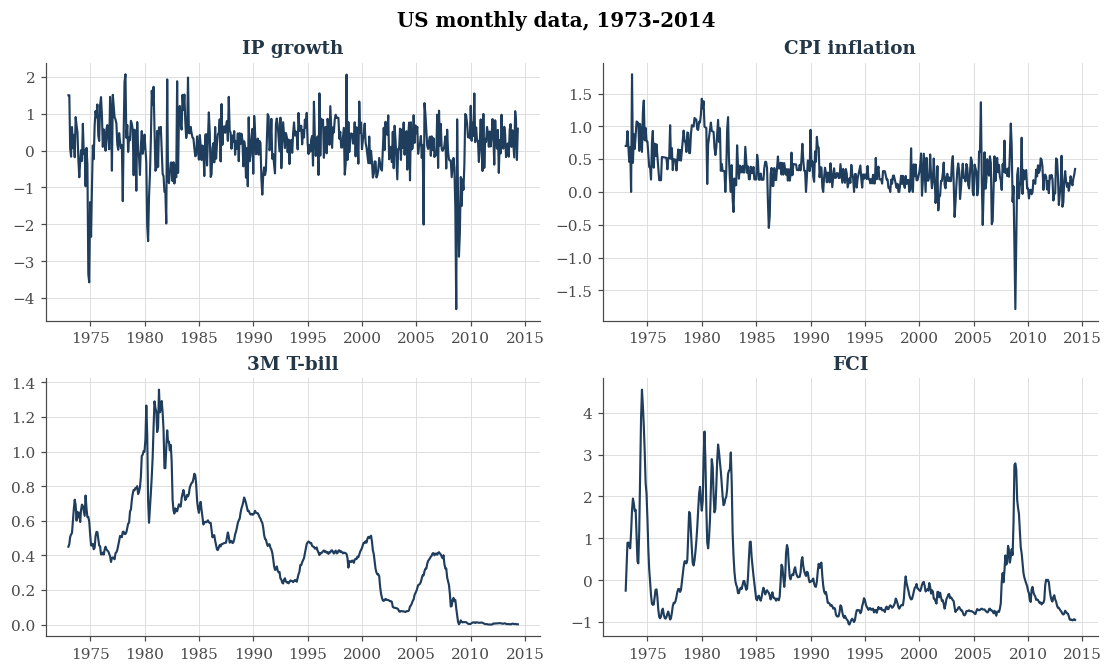

In [1]:
import numpy as np
import pandas as pd

from MacroPy import (
    ThresholdVAR, ThresholdVARSV, compare_threshold_models, generate_series_plot,
    plot_irf_comparison, plot_regime_comparison, plot_volatility_comparison,
)

df = pd.read_csv('../datasets/AlessandriMumtaz_Data.csv', index_col='date', parse_dates=True)
df.columns = ['ip_growth', 'inflation', 'tbill_3m', 'fci']
titles = ['IP growth', 'CPI inflation', '3M T-bill', 'FCI']
generate_series_plot(df, series_titles=titles, title='US monthly data, 1973-2014')

The data of Alessandri & Mumtaz (2019): industrial-production growth, CPI inflation, the 3-month
T-bill rate and the Chicago Fed financial conditions index (FCI, higher is tighter), ordered last.

## 2. Estimating both models

The authors' benchmark: $P = 13$ lags, delays up to 12 months, and for the TVAR-SV $J = 3$ lags of
$\ln\lambda_t$ in the mean. Both models drop the first 20 months after the lags (`training=20`, the
`ThresholdVARSV` default), so they are estimated on the same 464 observations. `irf_1std=0` asks
for unit structural shocks, comparable across models (Section 5).

The TVAR-SV is estimated by the authors' Gibbs sampler. The TVAR posterior is computed exactly:
with regime-specific covariances the dummy-observation prior is conjugate given the regimes, so the
marginal likelihood of every admissible split $(d, Z^*)$ has a closed form. The sampler draws the
split from that grid and then the coefficients and covariances independently, rejecting unstable
draws. A Gibbs sampler with a random-walk step for $Z^*$ targets the same posterior but, on these
data, stays near whichever split it starts from.

In [2]:
common = dict(threshold_var='fci', lags=13, max_delay=12, post_draws=8000, burnin=0.5,
              hor=48, irf_1std=0, seed=1234)
tvar = ThresholdVAR(df, training=20, **common)
tvar.sample_posterior()
tvarsv = ThresholdVARSV(df, vol_lags=3, **common)
tvarsv.sample_posterior()
models = {'TVAR': tvar, 'TVAR-SV': tvarsv}
print(f'TVAR proposals with both regimes stable: {tvar.stable_share:.0%}')

Sampling Posterior: 100%|██████████| 8000/8000 [01:01<00:00, 129.77it/s, acc=0.40, d=1, tar=0.655]


TVAR proposals with both regimes stable: 57%


## 3. Thresholds, delays and regimes

In [3]:
compare_threshold_models(models).T

,TVAR,TVAR-SV
specification,TVAR,TVAR-SV
sample,1975-10 to 2014-05,1975-10 to 2014-05
T,464,464
threshold (median),0.394218,0.687891
threshold p5,0.383771,0.628433
threshold p95,0.399391,0.75437
delay (mode),3,1
P(delay = mode),0.9995,0.75275
share in regime 2,0.179178,0.13385
dates with P(regime 2) > 0.5,83,62


Months classified alike: 94%


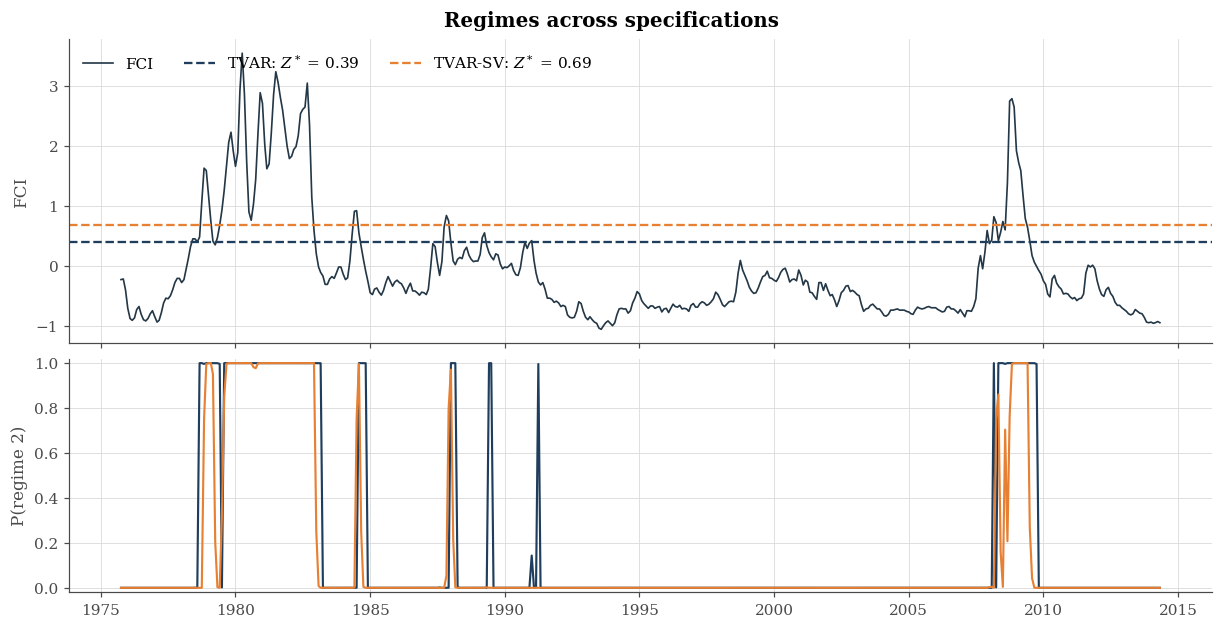

In [4]:
p_tvar, p_sv = tvar.regime_probability(), tvarsv.regime_probability()
print(f'Months classified alike: {((p_tvar > 0.5) == (p_sv > 0.5)).mean():.0%}')
plot_regime_comparison(models, var_label='FCI')

Both models find the same main episodes of financial distress, the late 1970s and the Volcker
disinflation, 1984, and 2008-09, and classify most months alike. They disagree on the threshold:
with stochastic volatility it is higher and the delay is one month, as in the paper, while the TVAR
sets a lower threshold with a three-month delay and adds short spells in 1989 and 1991. The TVAR
posterior of $Z^*$ is also much tighter: when the regimes carry the volatility, moving one month
across the threshold changes the fit of two covariance matrices.

## 4. Volatility: two regimes or a common factor

`residual_volatility` returns the posterior of each reduced-form shock's standard deviation over
time. In the TVAR it can take only two values.

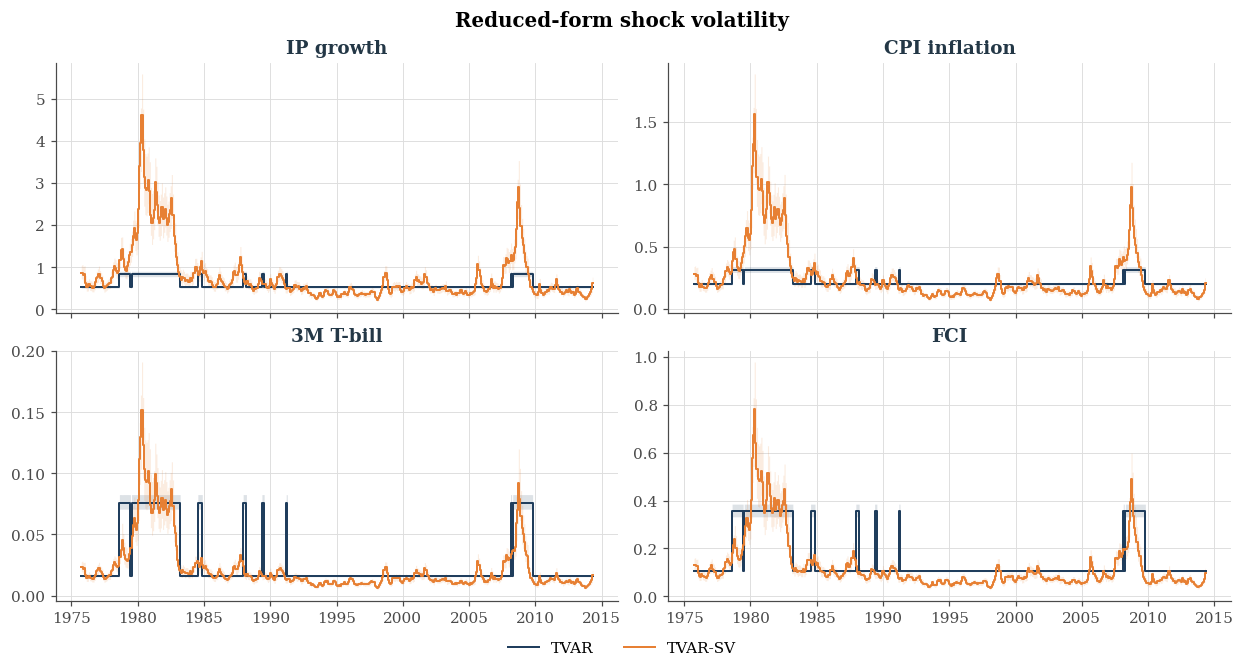

In [5]:
plot_volatility_comparison(models, series_titles=titles)

Stochastic volatility puts the standard deviation of output shocks above 4 in 1980 and near 3 in
late 2008, against 0.84 in the TVAR's distress regime, and lets it fall during the Great
Moderation. The TVAR averages volatility over all the distress months, and its threshold has to
classify volatility as well as dynamics.

That is also why a large Bayes factor in favour of the threshold model is not, on its own,
evidence of nonlinear dynamics. The exact posterior gives the TVAR's marginal likelihood against
a linear VAR with the same prior:

In [6]:
tvar.log_marginal_likelihood()

TVAR                902.059350
linear VAR          533.525784
log Bayes factor    368.533566
Name: log marginal likelihood, dtype: float64

A log Bayes factor in the hundreds rejects the linear, homoskedastic VAR, but a linear VAR with
stochastic volatility could capture much of the same gain.

## 5. Financial shocks in both models

Generalized impulse responses (Koop, Pesaran & Potter, 1996) to a Cholesky shock that raises the
FCI by 0.25 points on impact, between the TVAR's innovation standard deviations in the two regimes
(0.11 and 0.36). With unit shocks (`irf_1std=0`, `scale=0.25`) the impact is the same in every
model and regime, so the responses differ only through the dynamics.

Computing IRFs: 100%|██████████| 200/200 [00:56<00:00,  3.55it/s]


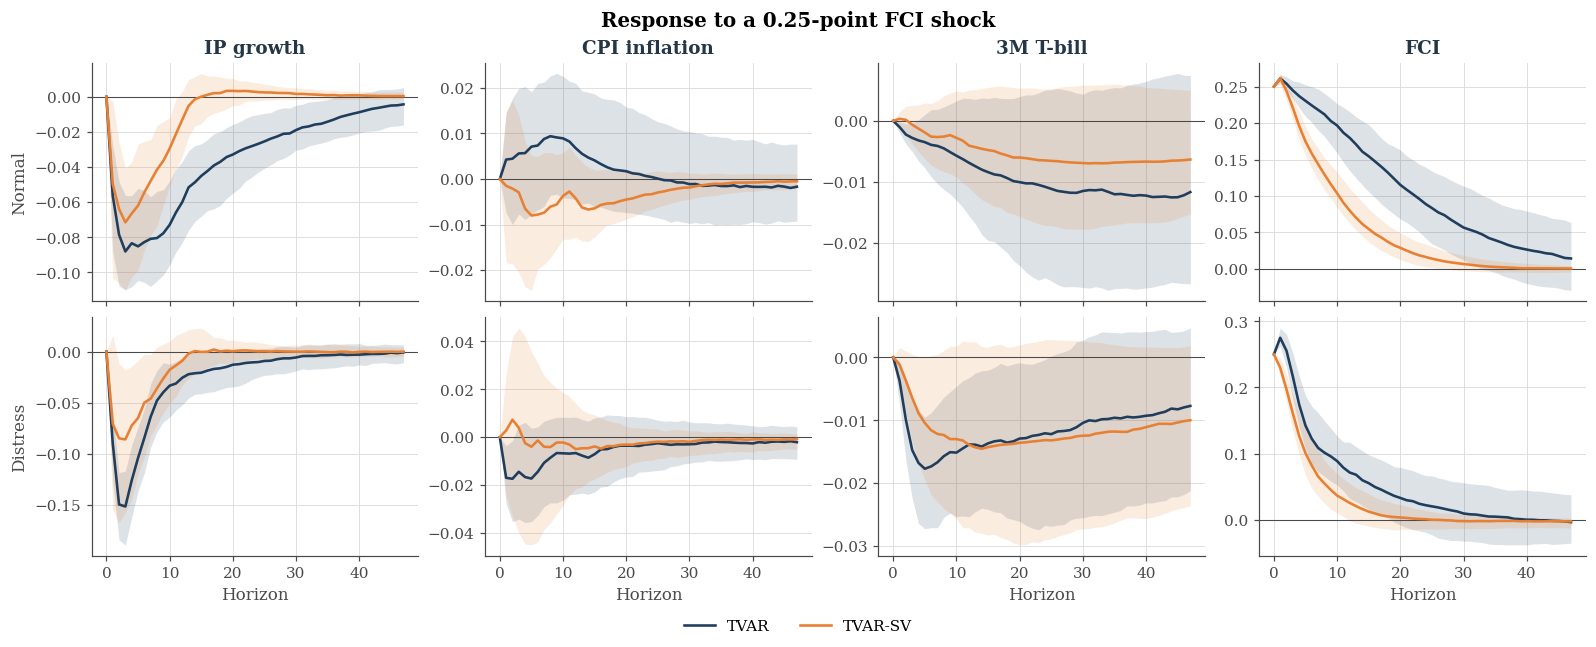

In [7]:
for model in models.values():
    model.compute_irfs(shock='level', n_draws=200, reps=25, scale=0.25)
plot_irf_comparison(
    models, shock='fci', regime_labels={1: 'Normal', 2: 'Distress'},
    series_titles=titles, title='Response to a 0.25-point FCI shock',
)

In [8]:
# Trough of the median IP-growth response to the FCI shock
trough = pd.DataFrame({
    name: {reg: np.median(m.irf[reg]['level'][:, :, 0, 3], axis=0).min()
           for reg in ('regime1', 'regime2')}
    for name, m in models.items()
}).T.rename(columns={'regime1': 'normal', 'regime2': 'distress'})
trough['distress / normal'] = trough['distress'] / trough['normal']
trough.round(3)

,normal,distress,distress / normal
TVAR,-0.088,-0.151,1.720
TVAR-SV,-0.071,-0.086,1.202


Tighter financial conditions lower output growth within a few months in both models, more in
distress. The amplification is larger without stochastic volatility, and the TVAR's normal-regime
responses are more persistent. The bands overlap for inflation and the T-bill rate.

## 6. Uncertainty shocks in the TVAR-SV

The central experiment of Alessandri & Mumtaz (2019): a one-standard-deviation innovation to
$\ln\lambda_t$, which raises the variance of every shock and, through the volatility-in-mean
terms, moves the conditional means.

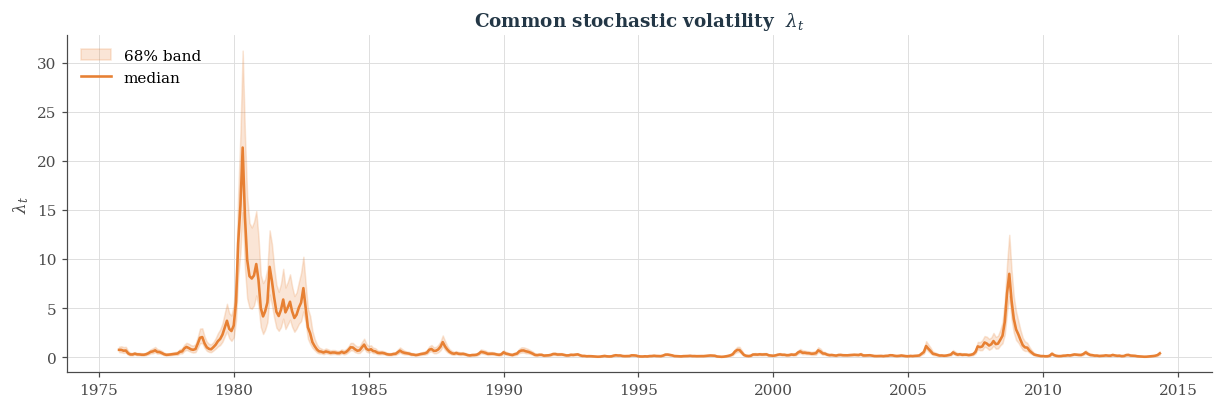

In [9]:
tvarsv.plot_volatility(cred=0.68)

Computing IRFs: 100%|██████████| 200/200 [00:24<00:00,  8.17it/s]


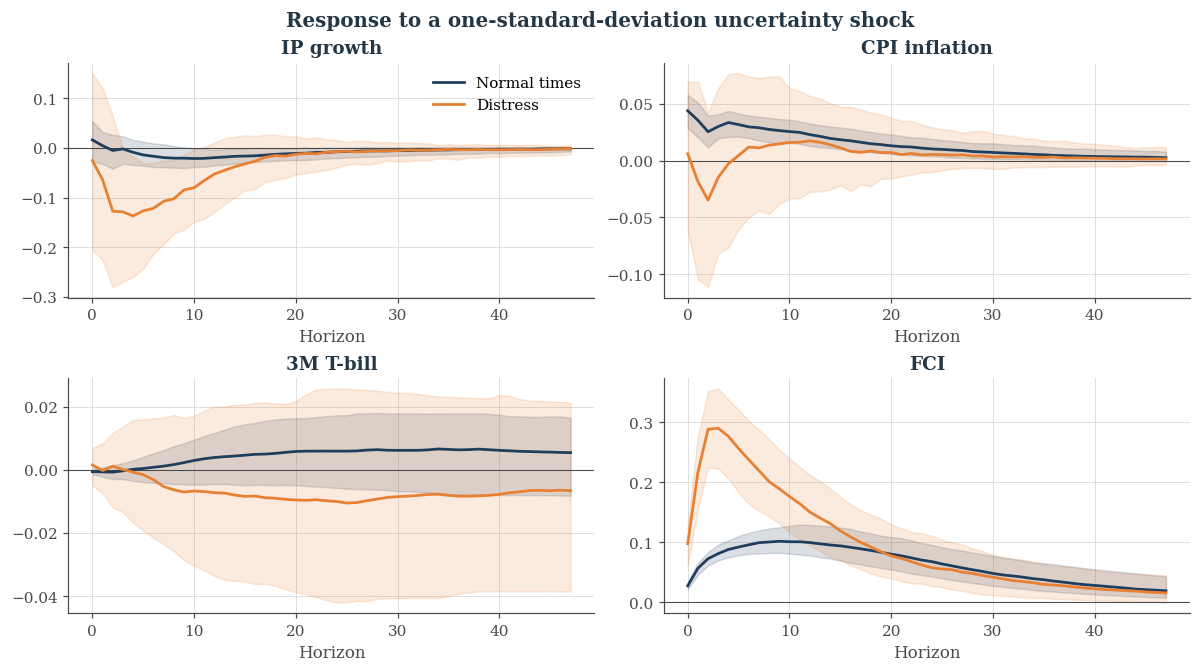

In [10]:
tvarsv.compute_irfs(shock='uncertainty', n_draws=200, reps=25)    # scale=1: one s.d. of eta
tvarsv.plot_irfs(
    shock='uncertainty', cred=0.68, series_titles=titles,
    regime_labels=('Normal times', 'Distress'),
    title='Response to a one-standard-deviation uncertainty shock',
)

In [11]:
# Trough of the median responses to the uncertainty shock
trough_u = pd.DataFrame({
    label: {var: np.median(tvarsv.irf[reg]['uncertainty'][:, :, i], axis=0).min()
            for i, var in enumerate(['ip_growth', 'inflation'])}
    for label, reg in (('normal', 'regime1'), ('distress', 'regime2'))
})
print(f"IP growth, distress / normal: {trough_u.loc['ip_growth', 'distress'] / trough_u.loc['ip_growth', 'normal']:.1f}")
trough_u.round(3)

IP growth, distress / normal: 6.5


,normal,distress
ip_growth,-0.021,-0.137
inflation,0.003,-0.035


This is the paper's main result: uncertainty shocks are recessionary mainly in financial distress,
where the trough of output growth is about six times deeper than in normal times and financial
conditions tighten far more. Inflation dips for a couple of months in distress and rises slightly
in normal times.

## 7. Notes

* `ThresholdVAR` draws from the exact posterior (`split_posterior` holds the posterior of every
  regime split, before the stability restriction). `log_marginal_likelihood` ignores the stability
  restriction.
* The estimation sample of both classes starts at `max(lags + training, max_delay)`, so every
  delay is evaluated on the same observations.
* GIRFs average over the sample histories of each regime and use common random numbers for the
  baseline and shocked paths. For published-quality bands raise `post_draws`, `n_draws` and `reps`.
* Both classes also produce density forecasts: `log_predictive_score` evaluates the predictive
  density at realised data, and `recursive_log_scores` and `compare_log_scores` compare models out
  of sample, as in Alessandri & Mumtaz (2017).

## References

- Alessandri, P. and Mumtaz, H. (2017). Financial conditions and density forecasts for US output and inflation. *Review of Economic Dynamics* 24, 66-78.
- Alessandri, P. and Mumtaz, H. (2019). Financial regimes and uncertainty shocks. *Journal of Monetary Economics* 101, 31-46.
- Banbura, M., Giannone, D. and Reichlin, L. (2010). Large Bayesian vector auto regressions. *Journal of Applied Econometrics* 25(1), 71-92.
- Chen, C.W.S. and Lee, J.C. (1995). Bayesian inference of threshold autoregressive models. *Journal of Time Series Analysis* 16(5), 483-492.
- Koop, G., Pesaran, M.H. and Potter, S.M. (1996). Impulse response analysis in nonlinear multivariate models. *Journal of Econometrics* 74(1), 119-147.